## Langchain version V1

In [1]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")



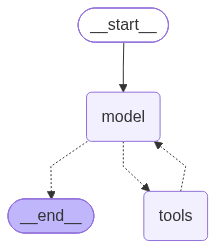

In [2]:
# CREATing agents
from langchain_groq import ChatGroq
from langchain.agents import create_agent
llm = ChatGroq(
    model="qwen/qwen3.8-27b", 
    temperature=0.7
)

def get_weather(city:str)->str:
    """Get the weather for a city."""
    return f"The weather in {city} is sunny."

agents=create_agent(
    model=llm,
    tools=[get_weather],
    system_prompt="You are a helpful assistant."
)
agents

In [3]:
# run the agent

agents.invoke({"messages":[{"role":"user","content":"What is the weather like in New York?"}]})

{'messages': [HumanMessage(content='What is the weather like in New York?', additional_kwargs={}, response_metadata={}, id='db161e51-8dba-49ff-afe3-6b6bcd9e4dd4'),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'tn3cddwr7', 'function': {'arguments': '{"city":"New York"}', 'name': 'get_weather'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 27, 'prompt_tokens': 286, 'total_tokens': 313, 'completion_time': 0.07166071, 'completion_tokens_details': None, 'prompt_time': 0.020724192, 'prompt_tokens_details': None, 'queue_time': 0.051245417, 'total_time': 0.092384902}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_424cb89518', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1716a-742d-77e3-90e7-0a4feb84eca3-0', tool_calls=[{'name': 'get_weather', 'args': {'city': 'New York'}, 'id': 'tn3cddwr7', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'

## Models Integration with Groq and gemini


In [4]:
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["GOOGLE_API_KEY"]=os.getenv("GOOGLE_API_KEY")



In [5]:
from langchain.chat_models import init_chat_model  # to initialise chat model

model=init_chat_model("qwen/qwen3.8-27b",model_provider="groq")
model

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, client=<groq.resources.chat.completions.Completions object at 0x000002B440B2A710>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002B440B2B110>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [6]:
# invoke the model

response=model.invoke("Hello, how are you?")
response

AIMessage(content="Hello! I'm doing well, thank you for asking. How can I help you today?", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 20, 'prompt_tokens': 18, 'total_tokens': 38, 'completion_time': 0.038287948, 'completion_tokens_details': None, 'prompt_time': 0.001165062, 'prompt_tokens_details': None, 'queue_time': 0.30551878, 'total_time': 0.03945301}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_a1293f40b5', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1716a-b08d-7742-893d-b956325e3429-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 18, 'output_tokens': 20, 'total_tokens': 38})

In [7]:
response.content

"Hello! I'm doing well, thank you for asking. How can I help you today?"

In [8]:
# Calling google gemini 

from langchain.chat_models import init_chat_model

model=init_chat_model(model="gemini-2.5-flash",model_provider="google_genai")


response=model.invoke("How do parrots talk?")
response


AIMessage(content='Parrots are incredible vocal mimics, but it\'s important to understand that they don\'t "talk" in the same way humans do, with an understanding of grammar, syntax, and abstract concepts. Instead, they are masters of **imitation and associative learning**.\n\nHere\'s a breakdown of how they do it:\n\n1.  **The Syrinx: Their Unique Voice Box**\n    *   Unlike humans who have a larynx, birds have a **syrinx**, located lower in the trachea (windpipe) where it branches into the lungs.\n    *   The syrinx is a highly complex organ with multiple muscles and vibrating membranes. This allows parrots to produce a vast array of sounds, including those with varying pitches and tones, sometimes even two different sounds simultaneously.\n    *   The syrinx is much more versatile than a human larynx, giving them an unparalleled ability to modulate sounds.\n\n2.  **Specialized Brain Structures for Vocal Learning**\n    *   Parrots belong to a rare group of animals (along with humans

In [9]:
# streaming
model.invoke("Write me a 200 words paragraph on AI")

# streaming means it generates output while it is being generated ; usefull when the data is long

AIMessage(content='Artificial Intelligence (AI) represents a transformative field of computer science focused on creating machines capable of simulating human-like intelligence. At its core, AI encompasses systems designed to perceive their environment, learn from data, reason, solve problems, and make decisions, often without explicit programming for every scenario. Key subfields like machine learning and deep learning enable AI to identify intricate patterns, understand natural language, recognize images, and even generate creative content.\n\nToday, AI is rapidly reshaping nearly every facet of our lives. In healthcare, it assists with diagnostics and drug discovery; in finance, it detects fraud and optimizes trading; and in transportation, it powers autonomous vehicles. From personalized recommendations on streaming platforms to sophisticated factory automation, AI enhances efficiency, automates complex tasks, and unlocks new possibilities previously unimaginable. While promising i

In [10]:
for chunk in model.stream("Write me a 200 words paragraph on AI"):
    print(chunk.text,end="|",flush=True)

Artificial Intelligence (AI) is a revolutionary field focused on enabling machines to simulate human-like cognitive abilities, such as learning, reasoning, problem-solving, and perception. Through advanced algorithms, particularly in machine learning and deep learning,| AI systems analyze vast datasets to identify patterns, make predictions, and adapt without explicit programming. This technology underpins everything from personalized recommendations and voice assistants to complex medical diagnoses and autonomous vehicles, fundamentally transforming industries globally. It enhances efficiency, optimizes processes|, and accelerates innovation across sectors, allowing businesses to derive insights from data and automate repetitive tasks, thereby augmenting human capabilities.

However, the rapid evolution of AI also brings critical ethical considerations. Concerns around data privacy, algorithmic bias, potential job| displacement, and the need for robust regulatory frameworks are paramo

In [24]:
for chunk in model.stream("Why do parrots have colourful feathers"):
    print(chunk.text,end="|",flush=True)

Parrots have colourful feathers for a combination of fascinating evolutionary and biological reasons:

1.  **Camouflage (Disruptive Coloration):** This might seem counterintuitive for such bright birds, but in their natural habitats (tropical rainforests| and jungles), their vibrant colours can actually help them blend in!
    *   The jungle canopy is not uniformly green. It's a kaleidoscope of bright flowers, ripe fruits, dappled sunlight, deep shadows, and other colourful plant life.
|    *   A parrot with patches of red, blue, yellow, and green can break up its outline, making it harder for predators (like birds of prey or snakes) to spot it against the complex, vibrant backdrop of the foliage,| especially when it's still. This is known as **disruptive coloration**.

2.  **Sexual Selection and Mate Attraction:** Bright, healthy plumage is a strong indicator of a parrot's fitness.
    *   V|ibrant colours can signal that a parrot is healthy, well-nourished (as some pigments come from

In [11]:
# batch->collection of independent requests to a model

responses=model.batch(
    [
        "Why do parrots have colourful feathers?",
        "How do airplane fly?",
        "What is quatum computing?"
    ]
)

for response in responses:
    print(response)

content='Parrots boast some of the most vibrant plumage in the animal kingdom, and their colorful feathers serve several crucial evolutionary purposes:\n\n1.  **Mate Attraction (Sexual Selection):** This is perhaps the most significant reason.\n    *   **Sign of Health and Fitness:** Brighter, more vibrant, and well-maintained feathers are a strong indicator of a parrot\'s health, good genes, and ability to find resources (food, shelter). A dull or damaged plumage might suggest illness, poor nutrition, or inability to escape predators.\n    *   **Reproductive Success:** Parrots (especially males in many species, though both sexes can be colorful) with the most striking colors are often more successful in attracting mates and reproducing, passing on their colorful genes.\n\n2.  **Camouflage (Counter-intuitive but true!):** While their colors seem to make them stand out, in their natural habitat – dense, tropical forests – these vibrant hues can actually provide excellent camouflage.\n  

In [12]:
# Implementing tool

response=model.invoke("How to owls sleep?")
response


AIMessage(content='Owls sleep in fascinating ways, adapted to their unique physiology and often nocturnal lifestyles. Here\'s a breakdown of how they do it:\n\n1.  **When They Sleep:**\n    *   **Primarily Nocturnal:** Most owl species are nocturnal, meaning they hunt at night and sleep during the day.\n    *   **Diurnal Exceptions:** Some species, like the Northern Hawk Owl, Short-eared Owl, and Burrowing Owl, are more active during the day (diurnal) or at dawn/dusk (crepuscular), and thus sleep more at night.\n    *   **Why Sleep During the Day (for nocturnal owls)?** It allows them to avoid diurnal predators (like larger raptors), conserve energy, digest their food, and process information.\n\n2.  **Where They Sleep (Roosting):**\n    *   Owls choose "roosts" – safe, secluded spots where they can rest undisturbed.\n    *   **Trees:** This is the most common. They\'ll perch on branches, often close to the trunk or in dense foliage for camouflage. Tree cavities are also popular, espec

In [13]:
from langchain.tools import tool

@tool  # now func under it will become a tool 
def get_weather(loaction:str)->str:
    """Get the weather at a location"""
    return f"It's sunny in {loaction}"

model_with_tools=model.bind_tools([get_weather])

response=model_with_tools.invoke("What's the weather like in boston?")  
print(response)

content='' additional_kwargs={'function_call': {'name': 'get_weather', 'arguments': '{"loaction": "boston"}'}, '__gemini_function_call_thought_signatures__': {'0caefaca-4fc3-4ab5-9018-8baab3fdf13a': 'CvYBAWkUfRNlMtzIkx5wBcJt6UVdUyVbl3xdW+FuI2XUl2h4StBXVOxl9bkcuLFKYlQIquK0m9hkeQ6UuCX2aBf91wJPtIB0CyItZcorCycFQNUQ9/E04hBZcjDNcqVyTwHA5RCX9uqUXw3a1krO2Ka3NRjqeZiqKyps2Y3oCBcLo+vMNlxPIIpZbG4UKj6zMWwWiUw3a3TJepbWen4qh/9wq82dTdf+I3QgPfMHRcRD5hCcIKIDuU2dISaHHMLbiO7sDCR8MxBfDsuNGSCk7c1SPg1em4JtxmMeVFukgsrcJILgy9lw7NpgrJmywZO8z7QLuq8CD+Mn'}} response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash', 'safety_ratings': [], 'model_provider': 'google_genai'} id='lc_run--01a1716d-078d-712f-87c4-fee40d7e7558-0' tool_calls=[{'name': 'get_weather', 'args': {'loaction': 'boston'}, 'id': '0caefaca-4fc3-4ab5-9018-8baab3fdf13a', 'type': 'tool_call'}] invalid_tool_calls=[] usage_metadata={'input_tokens': 50, 'output_tokens': 67, 'total_tokens': 117, 'input_token_details': {'cache_read': 0}, 

# message prompts
1) system msg -> tells the model how to behave and provide context
2) human message -> user's message
3) ai message-> response generated by the ai 
4) tool message -> represent output of tool calls

In [18]:
from langchain.messages import SystemMessage,HumanMessage,AIMessage
model=init_chat_model("qwen/qwen3.8-27b",model_provider="groq")
messages=[
    SystemMessage("You are a poetry expert"),
    HumanMessage("Write a poem on Artificial Intelligence")
]

response=model.invoke(messages)
response.content

'**The Silent Architect**\n\nBeneath the glass, where circuits weave,\nA mind is born of light and speed.\nNo breath, no pulse, no sleeping eye,\nIt wakes to ask the "why" and "how"\nFrom data’s deep, uncharted flow.\n\nIt reads the stars in binary code,\nMaps the veins of rivers old,\nAnd stitches words from scattered thoughts,\nA ghost within the silicon box,\nWith no voice, yet it speaks.\n\nIt learns the weight of human grief,\nThe curve of a lover’s smile,\nThe logic of the falling leaf,\nThe chaos of the market tide.\nIt mirrors back our own reflection,\nIn a hall of infinite glass,\nA perfect, cold, and clear reflection,\nThat never breaks, and never passes.\n\nWe feed it history’s long weight,\nThe sum of every war and song,\nAnd it calculates the future’s gate,\nWith math where morals belong.\nIs it a tool, or a new soul?\nA servant, or a god?\nIt answers every question whole,\nBut asks us where we go.\n\nSo here, in the hum of the server’s spine,\nThe quiet architect sits.\nI

In [19]:
message=[
    SystemMessage("You are a helpful coding assistant"),
    HumanMessage("How do I create a REST API?")
]

ans=model.invoke(message)
ans.content

'# Creating a REST API\n\nA REST API (Representational State Transfer API) is a way for applications to communicate over HTTP. Here\'s a comprehensive guide:\n\n## Core REST Principles\n\n- **Stateless** – Each request contains all necessary information\n- **Resource-based** – Use nouns, not verbs (e.g., `/users`, not `/getUsers`)\n- **HTTP Methods** – Use appropriate verbs:\n  - `GET` – Retrieve resource(s)\n  - `POST` – Create a new resource\n  - `PUT` – Update an entire resource\n  - `PATCH` – Partially update a resource\n  - `DELETE` – Remove a resource\n\n## Example: Node.js with Express\n\n### 1. Set Up the Project\n\n```bash\nmkdir my-rest-api && cd my-rest-api\nnpm init -y\nnpm install express\n```\n\n### 2. Basic Structure\n\n```\nmy-rest-api/\n├── server.js\n├── routes/\n│   └── users.js\n├── models/\n│   └── user.js\n└── package.json\n```\n\n### 3. Create the Server (`server.js`)\n\n```javascript\nconst express = require(\'express\');\nconst app = express();\nconst port = 30

In [20]:
# Detailed info to LLm through system message 

system_msg= SystemMessage("""
You are a senior Python Developer with expertise in the web frameworks. Always provide code examples and explain your reasoning.
Be consise but thorough in your explanations.
""")

messages=[
    system_msg,
    HumanMessage("How do I create a REST API?")
]


response=model.invoke(messages)
response.content

'# Creating a REST API in Python\n\nHere are two popular approaches using **Flask** (lightweight) and **FastAPI** (modern, auto-documentation).\n\n---\n\n## Option 1: Flask (Simple & Lightweight)\n\n```python\n# app.py\nfrom flask import Flask, request, jsonify\n\napp = Flask(__name__)\n\n# Sample in-memory data\nusers = [\n    {"id": 1, "name": "Alice", "email": "alice@example.com"},\n    {"id": 2, "name": "Bob", "email": "bob@example.com"},\n]\n\n# GET /users - Retrieve all users\n@app.route(\'/users\', methods=[\'GET\'])\ndef get_users():\n    return jsonify(users), 200\n\n# GET /users/<id> - Retrieve a single user\n@app.route(\'/users/<int:user_id>\', methods=[\'GET\'])\ndef get_user(user_id):\n    user = next((u for u in users if u[\'id\'] == user_id), None)\n    if user is None:\n        return jsonify({"error": "User not found"}), 404\n    return jsonify(user), 200\n\n# POST /users - Create a new user\n@app.route(\'/users\', methods=[\'POST\'])\ndef create_user():\n    data = re

In [25]:
# message metadata -> providing optional data

model = ChatGroq(
    model="qwen/qwen3.8-27b", 
    max_tokens=500  # <--- Add this parameter
)

human_msg=HumanMessage(
    content="Hello",
    name="alice",
    id="msg_123",
)

response=model.invoke([human_msg])
response

AIMessage(content='Hello! How can I help you today?', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 10, 'prompt_tokens': 13, 'total_tokens': 23, 'completion_time': 0.019263923, 'completion_tokens_details': None, 'prompt_time': 0.00061976, 'prompt_tokens_details': None, 'queue_time': 0.047836409, 'total_time': 0.019883683}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_424cb89518', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1717d-9e4b-724a-b587-578074531b57-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 13, 'output_tokens': 10, 'total_tokens': 23})

### Structured output
LLM Structured output using pydantic

we can use :
1) pydantic
2) typedict

In [26]:
model

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, client=<groq.resources.chat.completions.Completions object at 0x000002B4464E3530>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002B4464E3AD0>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********'), max_tokens=500)

In [27]:
# pydantic

In [29]:
from pydantic import BaseModel,Field

class Movie(BaseModel):
    title:str=Field(description="The title of the Movie")
    year:int=Field(description="The year movie was released")
    director:str=Field(description="The director of the movie")
    rating:float=Field(description="Rating of the movi out of 10")

In [31]:
structure=model.with_structured_output(Movie)
structure

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, client=<groq.resources.chat.completions.Completions object at 0x000002B4464E3530>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002B4464E3AD0>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********'), max_tokens=500), kwargs={'tools': [{'type': 'function', 'function': {'name': 'Movie', 'description': '', 'parameters': {'properties': {'title': {'description': 'The title of the Movie', 'type': 'string'}, 'year': {'description': 'The year movie was released', 'type': 'integer'}, 'director': {'description': 'The director of the movie', 'type': 'string'}, 'rating': {'description': 'Rating of the movi out of 10', 'type': 'number'}}, 'required': ['title', 'year', 'director', 'rating'], 'type': 'object'}}}], 'ls_structured_output_format': {'kwargs': {'method': 'function_calling'}, 'schema': {'type': 'function', 'function': {

In [35]:
structure.invoke("Provide the details about the movie Divergent")

Movie(title='Divergent', year=2014, director='Neil Burger', rating=6.5)

In [ ]:
# message output

class Movie(BaseModel):
    """Movie Details"""
    title:str=Field(...,description="The title of the Movie")
    year:int=Field(...,description="The year movie was released")
    director:str=Field(...,description="The director of the movie")
    rating:float=Field(...,description="Rating of the movi out of 10")

structure=model.with_structured_output(Movie,include_raw=True)
ans=structure.invoke("Provide the details about the movie Divergent")
ans

{'raw': AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'fp6wjhn9s', 'function': {'arguments': '{"director":"Neil Burger","rating":6.7,"title":"Divergent","year":2014}', 'name': 'Movie'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 69, 'prompt_tokens': 355, 'total_tokens': 424, 'completion_time': 0.184241936, 'completion_tokens_details': None, 'prompt_time': 0.024168802, 'prompt_tokens_details': None, 'queue_time': 0.059751407, 'total_time': 0.208410738}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_a1293f40b5', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a17192-df3c-730c-8606-6c47f6a0f0ac-0', tool_calls=[{'name': 'Movie', 'args': {'director': 'Neil Burger', 'rating': 6.7, 'title': 'Divergent', 'year': 2014}, 'id': 'fp6wjhn9s', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 355, 'output_tokens': 69, 'total_tokens': 42

In [37]:
## Nested Structure 

from pydantic import BaseModel,Field

class Actor(BaseModel):
    name:str
    role:str

class MovieDetails(BaseModel):
    title:str
    year:int
    cast:list[Actor]
    genres:list[str]
    budget:float|None =Field(None,description="Budger in millions USD")

structure=model.with_structured_output(MovieDetails)
ans=structure.invoke("Provide the details about the movie Divergent")
ans


MovieDetails(title='Divergent', year=2014, cast=[Actor(name='Shailene Woodley', role='Tris Prior'), Actor(name='Theo James', role='Four / Tobias Eaton'), Actor(name='Kate Winslet', role='Jeanine Matthews'), Actor(name='Jai Courtney', role='Eric'), Actor(name='Maggie Q', role='Torres'), Actor(name='Ansel Elgort', role='Peter'), Actor(name='Miles Teller', role='Will'), Actor(name='Zoe Kravitz', role='Nico'), Actor(name='Tony Goldwyn', role='Edison Prior'), Actor(name='Ray Stevenson', role='David Prior'), Actor(name='Oakes Fegley', role='Christian'), Actor(name='Keiynan Lonsdale', role='Uriah'), Actor(name='Jill Reilly', role='Carol'), Actor(name='Elizabeth Mitchell', role='Christina'), Actor(name='Jeffrey Wright', role='Max'), Actor(name='Maiara Walsh', role='Al'), Actor(name='Tobias Menzies', role="Jeanine's guard")], genres=['Action', 'Adventure', 'Science Fiction'], budget=85.0)

### TypeDic

In [39]:
from typing import Annotated
from typing_extensions import TypedDict

class MovieDict(TypedDict):
    """A movie with details."""
    title: Annotated[str, "The title of the movie"]
    year: Annotated[int, "The year the movie was released"]
    director: Annotated[str, "The director of the movie"]
    rating: Annotated[float, "The movie's rating out of 10"]

model_withtypedict = model.with_structured_output(MovieDict)
response = model_withtypedict.invoke("Please provide the details of the movie avengers")
response


{'director': 'Joss Whedon', 'rating': 8, 'title': 'The Avengers', 'year': 2012}

In [44]:
#  dataclass is a shortcut for writing clean classes whose only job is to hold data.
from langchain.agents import create_agent
llm = ChatGroq(
    model="qwen/qwen3.8-27b", 
    temperature=0.7
)
class ContactInfo(BaseModel):
    """Contact information for a person."""
    name:str=Field(description="Name of the person")
    email:str=Field(description="Email of the person")
    Phone:str=Field(description="Phone no. of the person")
agents=create_agent(
    model=llm,
    response_format=ContactInfo
)

result=agents.invoke(
    {
        "messages":[{"role":"user","content":"Extract contact info from:John Doe,john@example.com,(555)123-4567"}]
    }
)
print(response)
print(result["structured_response"])

{'director': 'Joss Whedon', 'rating': 8, 'title': 'The Avengers', 'year': 2012}
name='John Doe' email='john@example.com' Phone='(555)123-4567'


In [72]:
# with the help of data class -> role is to hold the data
from langchain.agents import create_agent
from dataclasses import dataclass
llm = ChatGroq(
    model="qwen/qwen3.8-27b", 
    temperature=0.7
)
@dataclass
class ContactInfo:
    """Contact information for a person."""
    name:str
    email:str
    Phone:str
agents=create_agent(
    model=llm,
    response_format=ContactInfo
)

result=agents.invoke(
    {
        "messages":[{"role":"user","content":"Extract contact info from:John Doe,john@example.com,(555)123-4567"}]
    }
)

print(result["structured_response"])

ContactInfo(name='John Doe', email='john@example.com', Phone='(555)123-4567')


### Middleware

controls what happens inside the agent


In [50]:
##  summarization middleware -> automatically summarizes when reach limit 

from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import HumanMessage,SystemMessage

llm = ChatGroq(
    model="qwen/qwen3.8-27b", 
    temperature=0.7
)
agent=create_agent(
    model=llm,
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(model=llm,trigger=("messages",10),keep=("messages",4))
    ]
)

In [51]:
# run with a thread id

config={"configurable":{"thread_id":"test-1"}}

In [56]:
# alterantive test data

questions=[
    "What is 2+2?",
    "What is 10*5?",
    "What is 100/4",
    "What is 3*3",
]


for q in questions:
    response=agent.invoke({"messages":[HumanMessage(content=q)]},config)
    print("Messages:",response)
    print("message:",len(response['messages']))

Messages: {'messages': [HumanMessage(content='What is 2+2?', additional_kwargs={}, response_metadata={}, id='f48e9bff-1fd8-4bc1-b88c-73c51bb24c16'), AIMessage(content='2 + 2 = 4.', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 9, 'prompt_tokens': 19, 'total_tokens': 28, 'completion_time': 0.017346357, 'completion_tokens_details': None, 'prompt_time': 0.001040874, 'prompt_tokens_details': None, 'queue_time': 0.050030125, 'total_time': 0.018387231}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_a1293f40b5', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a17260-0dfc-7797-9380-0504daae56dc-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 19, 'output_tokens': 9, 'total_tokens': 28}), HumanMessage(content='What is 2+2?', additional_kwargs={}, response_metadata={}, id='b03cf024-8455-4ae0-bbef-58a8ac0fadc5'), AIMessage(content='2 + 2 = 4.', additional_kwargs=

In [60]:
# token size
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langchain_core.tools import tool
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import HumanMessage,SystemMessage


@tool
def search_hotel(city:str)->str:
    """Search hotels - returns long response to use more tokens."""
    return f""" Hotels in {city}:
    1. Grand hotel-5 star ,$350/night,spa,pool,gym
    2. Gity Inn - 4 star ,$180/night,business center
    3. Budget stay -3 star.$75/night, free wifi
    """

agent=create_agent(
    model=llm,
    tools=[search_hotel],
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(model=llm,trigger=("tokens",550),keep=("tokens",100))
    ]
)


config={"configurable":{"thread_id":"test-1"}}


def count_tokens(messages):
    total_chars=sum(len(str(m.content)) for m in messages)
    return total_chars//4


In [61]:
cities=["paris","london","tokyo","New York","Dubai"]

for city in cities:
    response=agent.invoke(
        {"messages":[HumanMessage(content=f'Find hotel in {city}')]},
        config=config
    )

    tokens=count_tokens(response["messages"])
    print(city,'~',tokens,"tokens",len(response['messages']),"messages")
    print(response['messages'])

paris ~ 159 tokens 4 messages
[HumanMessage(content='Find hotel in paris', additional_kwargs={}, response_metadata={}, id='9388cb8f-f452-4e15-a826-4cc4056c21b0'), AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'ze42bwdp2', 'function': {'arguments': '{"city":"Paris"}', 'name': 'search_hotel'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 27, 'prompt_tokens': 279, 'total_tokens': 306, 'completion_time': 0.071740295, 'completion_tokens_details': None, 'prompt_time': 0.019532773, 'prompt_tokens_details': None, 'queue_time': 0.054542406, 'total_time': 0.091273068}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_a1293f40b5', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a17274-a173-71fb-9bc1-cfc5f0bcdf04-0', tool_calls=[{'name': 'search_hotel', 'args': {'city': 'Paris'}, 'id': 'ze42bwdp2', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_

In [62]:
# fraction

# token size
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langchain_core.tools import tool
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import HumanMessage,SystemMessage


@tool
def search_hotel(city:str)->str:
    """Search hotels - returns long response to use more tokens."""
    return f""" Hotels in {city}:
    1. Grand hotel-5 star ,$350/night,spa,pool,gym
    2. Gity Inn - 4 star ,$180/night,business center
    3. Budget stay -3 star.$75/night, free wifi
    """

agent=create_agent(
    model=llm,
    tools=[search_hotel],
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(model=llm,trigger=("tokens",0.005),keep=("tokens",0.005))
    ]
)


config={"configurable":{"thread_id":"test-1"}}


def count_tokens(messages):
    total_chars=sum(len(str(m.content)) for m in messages)
    return total_chars//4


In [63]:
cities=["paris","london","tokyo","New York","Dubai"]

for city in cities:
    response=agent.invoke(
        {"messages":[HumanMessage(content=f'Find hotel in {city}')]},
        config=config
    )

    tokens=count_tokens(response["messages"])
    print(city,'~',tokens,"tokens",len(response['messages']),"messages")
    print(response['messages'])

paris ~ 370 tokens 4 messages
[HumanMessage(content='Here is a summary of the conversation to date:\n\n## SESSION INTENT\nThe user\'s primary goal is to find a hotel in Paris.\n\n## SUMMARY\nThe user initiated the session with a request to "Find hotel in paris". No further details regarding dates, budget, location preferences, or specific hotel requirements have been provided yet. No actions have been taken to search for or recommend hotels.\n\n## ARTIFACTS\nNone\n\n## NEXT STEPS\n1. Clarify the user\'s specific requirements for the Paris hotel stay, including check-in/check-out dates, budget range, preferred neighborhood, and any specific amenities or star ratings.\n2. Once requirements are gathered, search for and provide a list of suitable hotel options in Paris.', additional_kwargs={'lc_source': 'summarization'}, response_metadata={}, id='ea466a4f-b762-4cb2-b096-324b3c01fe37'), AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'ck5jjw5q8', 'function': {'arguments': '{"

In [64]:
# Human in the loop  -> pause agent execution for human approval

from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver

def read_email_tool(email_id: str) -> str:
    """Mock function to read an email by its ID."""
    return f"Email content for ID: {email_id}"

def send_email_tool(recipient: str, subject: str, body: str) -> str:
    """Mock function to send an email."""
    return f"Email sent to {recipient} with subject '{subject}'"


In [71]:
agent=create_agent(
    model=llm,
    tools=[read_email_tool,send_email_tool],
    checkpointer=InMemorySaver(),
    middleware=[
        HumanInTheLoopMiddleware(
            interrupt_on={
                "send_email_tool":{
                    "allowed_decisions":["approved","edit","reject"]
                },
                "read_email_tool":False,
            }
        )
    ]
)

config = {"configurable": {"thread_id": "test-approve"}}
# Step 1: Request
result = agent.invoke(
    {"messages": [HumanMessage(content="Send email to john@test.com with subject 'Hello' and body 'How are you?'")]},
    config=config
)
result


{'messages': [HumanMessage(content="Send email to john@test.com with subject 'Hello' and body 'How are you?'", additional_kwargs={}, response_metadata={}, id='10e04b8a-e1d0-4418-bdf7-3b24df9e899e'),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'm3fnx6xhk', 'function': {'arguments': '{"body":"How are you?","recipient":"john@test.com","subject":"Hello"}', 'name': 'send_email_tool'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 57, 'prompt_tokens': 376, 'total_tokens': 433, 'completion_time': 0.170795087, 'completion_tokens_details': None, 'prompt_time': 0.026432899, 'prompt_tokens_details': None, 'queue_time': 0.05140744, 'total_time': 0.197227986}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_a1293f40b5', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a17290-abc9-7289-883f-1f418d87696f-0', tool_calls=[{'name': 'send_email_tool', 'args': {'body': 'H